# Session 4: Convolutional Neural Networks and Filters

This notebook contains structured tasks based on Session 4 materials.

**Instructions:**
- Do NOT use a separate `.py` file. Complete all tasks directly in this notebook.
- Keep your code clear and well-commented.
- For Visulaization, please use `%matplotlib inline`
- Submit your completed notebook by uploading it to your forked repository.

### ***DO NOT UPLOAD THE DATASET TO GITHUB as it's too large***
<hr>

## Task 1: Convolutional Filters on an Image
Apply several 2D filters (Sobel X, Sobel Y, Laplacian, and Sharpen) to an image and visualize the results side by side.

**Hint:**
- Use OpenCV (`cv2.filter2D`) or NumPy to apply kernels.
- Define common kernels (Sobel, Laplacian, Sharpen).
- Use `matplotlib.pyplot` to plot the original and filtered images.

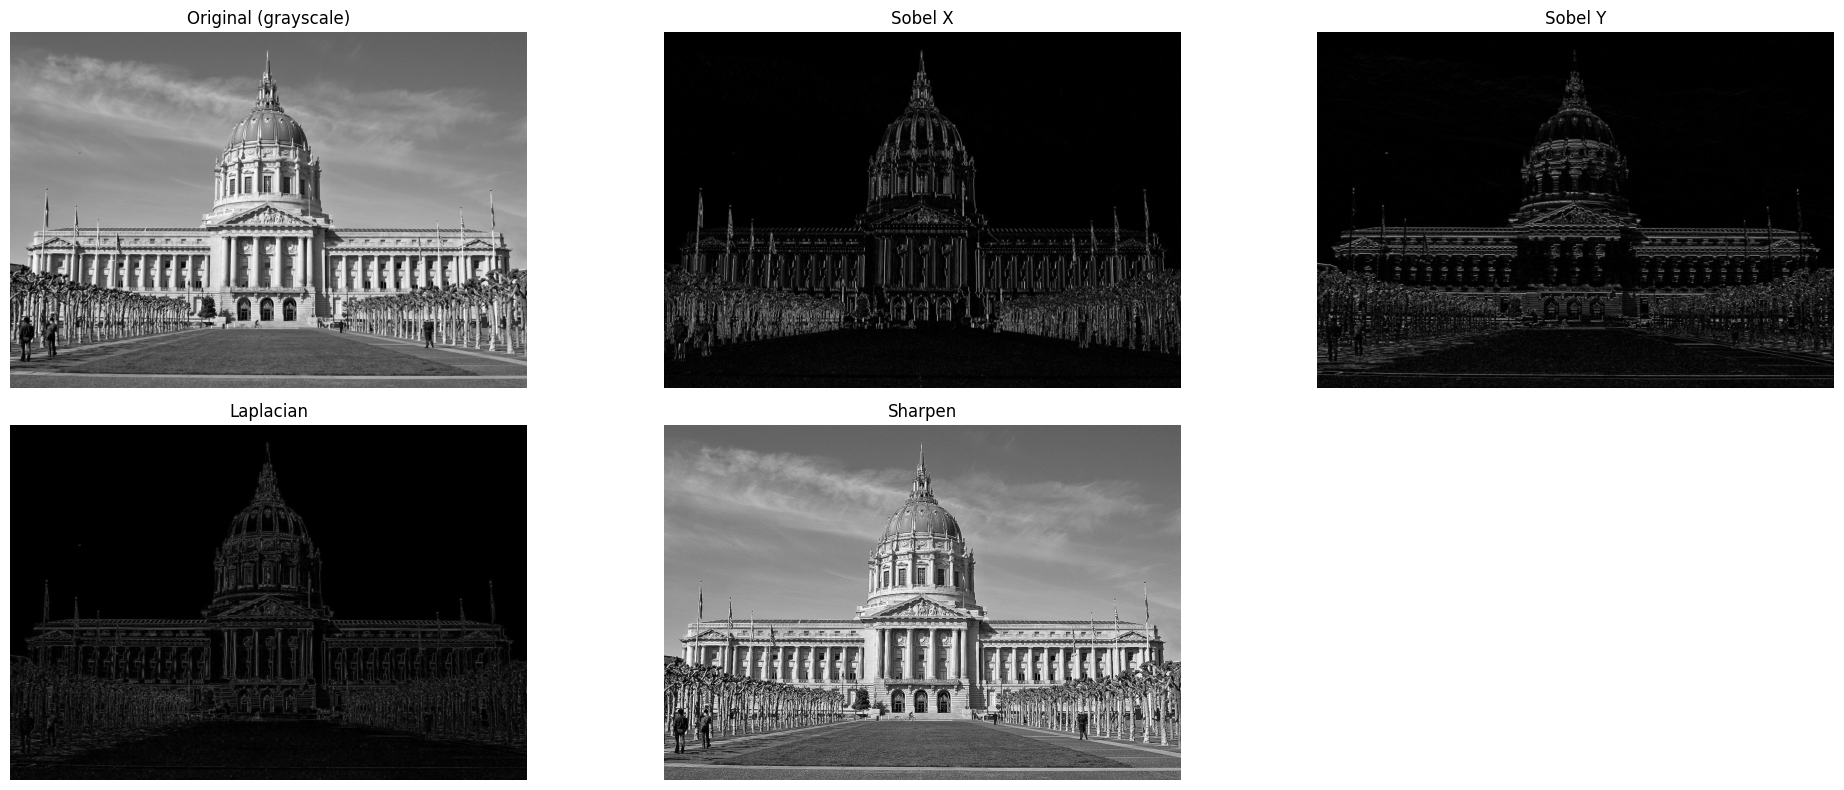

In [1]:
%matplotlib inline
import cv2
import numpy as np
import matplotlib.pyplot as plt

# TODO: Load an image (use OpenCV or matplotlib)
image_path = r'C:\Users\habib\OneDrive\Desktop\gettingintoit\skyexperts CV training\Session4\Convolutional_Filters_Edge_Detection\images\city_hall.jpg'
image = cv2.imread(image_path)
if image is None:
    raise FileNotFoundError(f"could not read the image at: {image_path}")

# TODO: Convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# TODO: Define Sobel, Laplacian, and Sharpen kernels
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]], dtype=np.float32)    # left-right change -> vertical edges
sobel_y = np.array([[-1, -2, -1],
                    [0, 0, 0],
                    [1, 2, 1]], dtype=np.float32)     # up-down change -> horizontal edges
laplacian = np.array([[0, 1, 0],
                      [1, -4, 1],
                      [0, 1, 0]], dtype=np.float32)   # change in every direction
sharpen = np.array([[0, -1, 0],
                    [-1, 5, -1],
                    [0, -1, 0]], dtype=np.float32)    # original + its edges

# TODO: Apply each filter to the image
# CV_64F keeps the negative values of the edge filters; abs() then shows both sides of an edge as bright
filtered_sobel_x = np.abs(cv2.filter2D(gray, cv2.CV_64F, sobel_x))
filtered_sobel_y = np.abs(cv2.filter2D(gray, cv2.CV_64F, sobel_y))
filtered_laplacian = np.abs(cv2.filter2D(gray, cv2.CV_64F, laplacian))
filtered_sharpen = cv2.filter2D(gray, -1, sharpen)   # a normal picture, so uint8 (0-255) is what we want

# TODO: Plot results in a grid using matplotlib
plt.figure(figsize=(20, 8))
for i, (picture, title) in enumerate([(gray, 'Original (grayscale)'),
                                      (filtered_sobel_x, 'Sobel X'),
                                      (filtered_sobel_y, 'Sobel Y'),
                                      (filtered_laplacian, 'Laplacian'),
                                      (filtered_sharpen, 'Sharpen')]):
    plt.subplot(2, 3, i + 1)
    plt.imshow(picture, cmap='gray')
    plt.title(title)
    plt.axis('off')
plt.tight_layout()
plt.show()

## Task 2: Build a Simple CNN on FashionMNIST
Construct and train a small Convolutional Neural Network (CNN) on the FashionMNIST dataset.

**Hint:**
- Use `torchvision.datasets.FashionMNIST` for loading data.
- Define a small CNN with `nn.Conv2d`, `nn.ReLU`, `nn.MaxPool2d`, and `nn.Linear`.
- Train for a few epochs using an optimizer (e.g., Adam) and loss function (e.g., CrossEntropyLoss).
- Print training accuracy after each epoch.

In [2]:
# TODO: Import torch, torchvision, and related libraries
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(0)   # same random start every run

# TODO: Load FashionMNIST dataset with transforms
# the dataset is already downloaded in the Session4 folder, so i reuse it instead of downloading it again
data_dir = r'C:\Users\habib\OneDrive\Desktop\gettingintoit\skyexperts CV training\Session4\CNN_Layers\data'
transform = transforms.ToTensor()   # image -> tensor of shape (1, 28, 28) with values 0-1

train_data = datasets.FashionMNIST(root=data_dir, train=True, download=True, transform=transform)
test_data = datasets.FashionMNIST(root=data_dir, train=False, download=True, transform=transform)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

classes = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
           'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
print('train images:', len(train_data), '| test images:', len(test_data))

# TODO: Define a simple CNN class with one conv layer and one fc layer
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)   # 1 gray channel in, 16 learned filters out, 28x28 stays 28x28
        self.relu = nn.ReLU()                                     # negatives become 0
        self.pool = nn.MaxPool2d(2, 2)                            # 28x28 -> 14x14
        self.fc1 = nn.Linear(16 * 14 * 14, 10)                    # 16 maps of 14x14 -> 10 class scores

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = x.view(x.size(0), -1)   # flatten each image's maps into one long vector
        return self.fc1(x)

net = Net()
print(net)

# TODO: Set up optimizer and loss function
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(net.parameters(), lr=0.001)

# TODO: Implement a short training loop (2-3 epochs)
epochs = 3
for epoch in range(epochs):
    net.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        optimizer.zero_grad()               # 1. clear the old gradients
        outputs = net(images)               # 2. forward pass: predictions
        loss = criterion(outputs, labels)   # 3. how wrong the predictions are
        loss.backward()                     # 4. backward pass: gradients
        optimizer.step()                    # 5. update the weights

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    print(f'epoch {epoch + 1}/{epochs}: loss {running_loss / total:.4f}, training accuracy {100 * correct / total:.2f}%')

# check on images the network never saw during training
net.eval()
correct, total = 0, 0
with torch.no_grad():
    for images, labels in test_loader:
        correct += (net(images).argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
print(f'test accuracy: {100 * correct / total:.2f}%')

train images: 60000 | test images: 10000
Net(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=10, bias=True)
)
epoch 1/3: loss 0.4908, training accuracy 83.04%
epoch 2/3: loss 0.3278, training accuracy 88.45%
epoch 3/3: loss 0.2924, training accuracy 89.60%
test accuracy: 89.14%


## Task 3: Visualize Feature Maps
Visualize feature maps produced by the first convolutional layer of your CNN.

**Hint:**
- Take a single image from the test set.
- Pass it through the first convolutional layer (`net.conv1`).
- Convert the output to NumPy and plot several channels as images.

feature maps shape: (16, 28, 28)


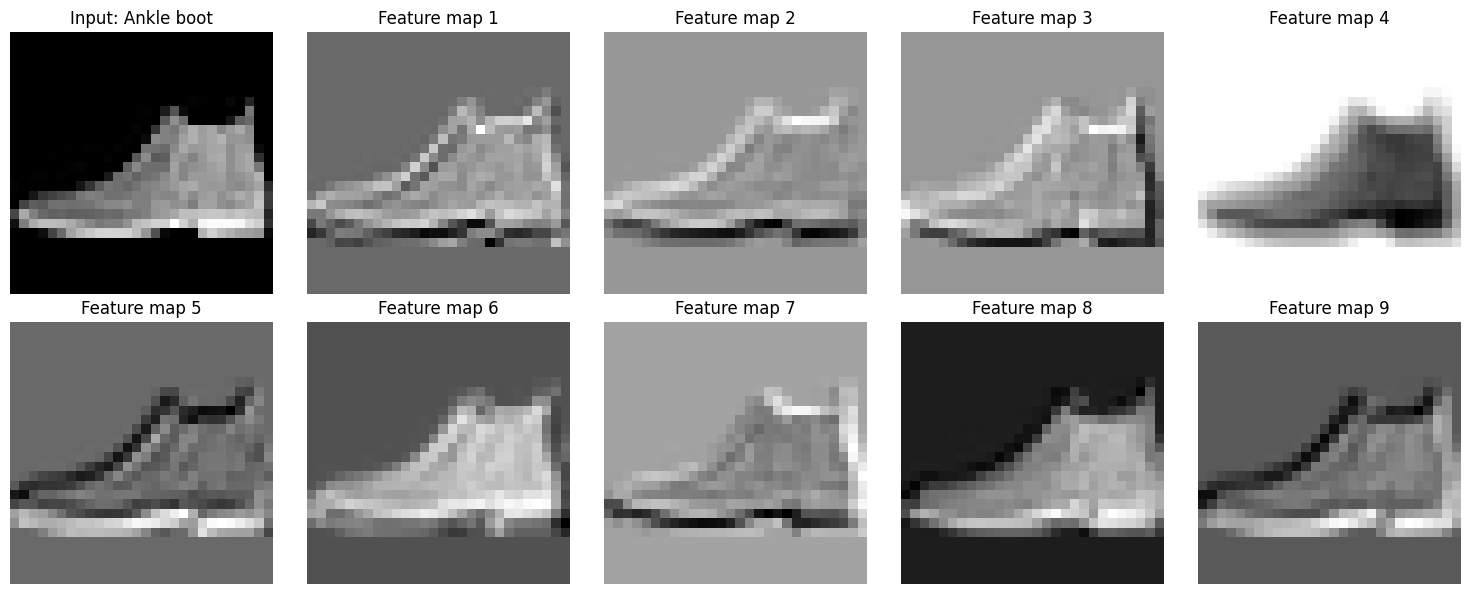

In [3]:
# TODO: Take one test image
test_image, test_label = test_data[0]     # tensor of shape (1, 28, 28)

# TODO: Forward pass through the first convolutional layer
net.eval()
with torch.no_grad():
    feature_maps = net.conv1(test_image.unsqueeze(0))   # unsqueeze adds the batch dimension: (1, 1, 28, 28)

# TODO: Convert feature maps to NumPy array
feature_maps = feature_maps.squeeze(0).numpy()          # (16, 28, 28): one map per learned filter
print('feature maps shape:', feature_maps.shape)

# TODO: Plot the first few feature maps in a grid
plt.figure(figsize=(15, 6))
plt.subplot(2, 5, 1)
plt.imshow(test_image.squeeze(), cmap='gray')
plt.title(f'Input: {classes[test_label]}')
plt.axis('off')
for i in range(9):
    plt.subplot(2, 5, i + 2)
    plt.imshow(feature_maps[i], cmap='gray')
    plt.title(f'Feature map {i + 1}')
    plt.axis('off')
plt.tight_layout()
plt.show()

## Task 4: Haar Cascade Face Detection

Apply Haar Cascade classifiers for basic object detection (faces).

**Hint:**
- Use `cv2.CascadeClassifier` with a pre-trained XML file (e.g., `haarcascade_frontalface_default.xml`).
- Convert the input image to grayscale before detection.
- Use `detectMultiScale` to get bounding boxes.
- Draw rectangles on detected faces with `cv2.rectangle`.
- Visualize with Matplotlib.


faces found: 13


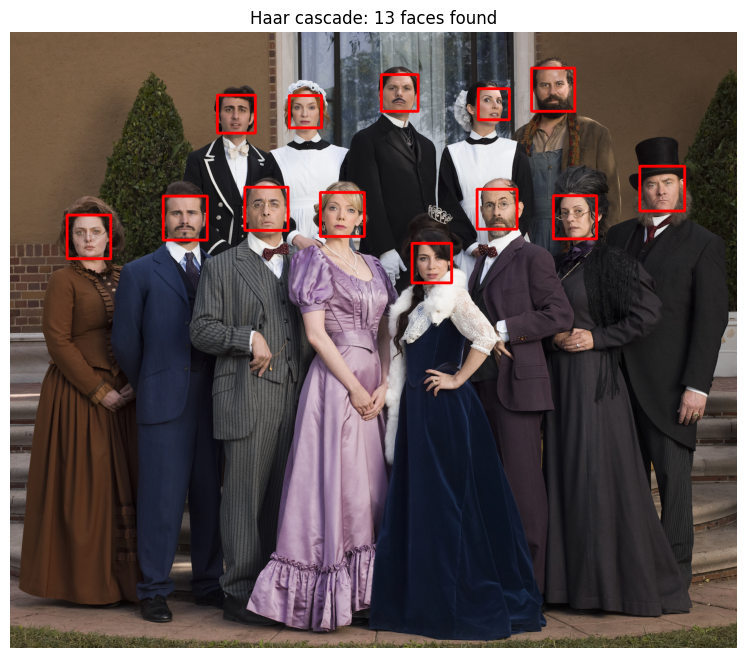

In [4]:
# TODO: Load an image containing a face
face_path = r'C:\Users\habib\OneDrive\Desktop\gettingintoit\skyexperts CV training\Session4\Convolutional_Filters_Edge_Detection\images\multi_faces.jpg'
face_image = cv2.imread(face_path)
if face_image is None:
    raise FileNotFoundError(f"could not read the image at: {face_path}")

# TODO: Convert to grayscale
face_gray = cv2.cvtColor(face_image, cv2.COLOR_BGR2GRAY)

# TODO: Load Haar Cascade XML (frontal face) || cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
# my OpenCV 5 install doesn't ship the XML files in cv2.data.haarcascades, so i load the one from the Session4 folder
cascade_path = r'C:\Users\habib\OneDrive\Desktop\gettingintoit\skyexperts CV training\Session4\Convolutional_Filters_Edge_Detection\detector_architectures\haarcascade_frontalface_default.xml'
face_cascade = cv2.CascadeClassifier(cascade_path)
if face_cascade.empty():
    raise FileNotFoundError(f"could not load the Haar cascade XML at: {cascade_path}")

# TODO: Apply detectMultiScale to find faces
# scaleFactor: how much the image shrinks at each step (to find faces of different sizes)
# minNeighbors: how many overlapping detections a face needs before it counts (higher = fewer false alarms)
faces = face_cascade.detectMultiScale(face_gray, scaleFactor=1.3, minNeighbors=8)
print('faces found:', len(faces))

# TODO: Draw bounding boxes on the original image
result = face_image.copy()
for (x, y, w, h) in faces:
    cv2.rectangle(result, (x, y), (x + w, y + h), (0, 0, 255), 6)   # red in BGR

# TODO: Display results with matplotlib
plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title(f'Haar cascade: {len(faces)} faces found')
plt.axis('off')
plt.show()